# RF microstrip: quarter wave stub filter
 Quarter wave stub bandstop filter in RF microstrip with nominal 5GHz notch

[Run in Lumi Colab](https://colab.luminescentai.com/hub/user-redirect/lab/tree/tutorials/RF_circuits/stub_filter/stub_filter.ipynb)

## Setup 

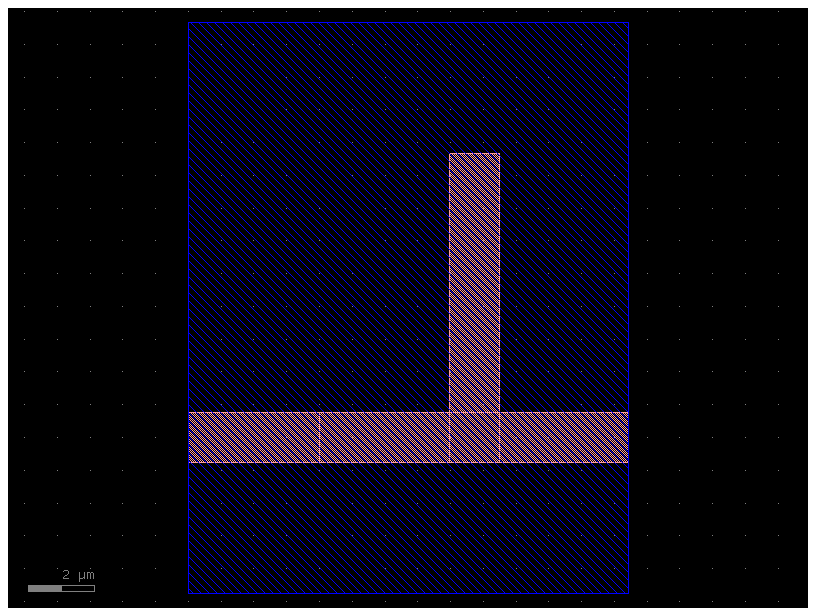

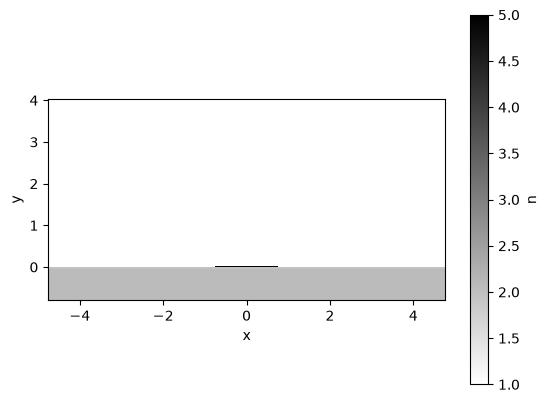

using simulation folder runs/stub_filter


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

import gdsfactory as gf
from gdsfactory.technology import LogicalLayer, LayerLevel, LayerStack
import luminescent as lumi

# simulation folder
path = os.path.join("runs", "stub_filter")

# dims [mm]
# length units are arbitrary so long as they're consistent
w_line = 1.52  # strip width
h_metal = 0.035  # metal thickness
h_sub = 0.8  # substrate thickness
eps_sub = 4.3
v_rel = 87.5 / 139  # relative signal speed, from microstrip calculator

# frequencies [GHz]
# spectrum computed from single FDTD run. more frequencies slightly increases runtime
frequency = 5
bandwidth = 4
nfs = bandwidth * 25+1
frequencies = np.linspace(frequency - bandwidth / 2, frequency + bandwidth / 2, nfs)

c0 = 300  # speed of light [mm GHz]

# quarter-wave stub at center frequency
l_stub = c0 / frequency * v_rel / 4
l_feed = l_stub


def setup(path, frequency, frequencies, w_line, h_metal, h_sub, eps_sub, l_stub, l_feed):
    # simulation parameters
    nres = 16
    dx = h_sub / 6  # desired resolution in metal
    shutoff = 1e-2
    tmax = 1000  # max time [periods]
    PML_decay = [0.001,.1,.1]
    courant = 0.9
    shot_every =.5 # movie [periods]

    # margins
    zmargin =margin = 5 * h_sub
    source_offset = 5 * h_sub

    # ground plane as PEC boundary on z-
    boundaries = ["PML", "PML", ("PEC", "PML")]

    # vertical dims
    zmin = -h_sub
    zmax = h_metal + zmargin

    views = [
        lumi.view("Ez", x=-source_offset, y=0, z=-h_sub / 2),
        lumi.view("Hz", z=h_metal / 2),
    ]

    # materials
    # refine mesh in metal: n sets mesh density relative to vacuum
    n = (c0 / frequency / nres) / dx
    materials = {
        "air": lumi.material(1),
        "sub": lumi.material(epsilon=eps_sub),
        "PEC": lumi.PEC_material(n),
    }
    background = "air"

    # layers
    TRACE = 1, 0
    SUB = 10, 0
    layer_stack = LayerStack(
        layers={
            "trace": LayerLevel(
                layer=LogicalLayer(layer=TRACE),
                thickness=h_metal,
                zmin=0,
                material="PEC",
                mesh_order=10,
            ),
            "sub": LayerLevel(
                layer=LogicalLayer(layer=SUB),
                thickness=h_sub,
                zmin=-h_sub,
                material="sub",
                mesh_order=30,
            ),
        }
    )

    # make component in gdsfactory. alternatively can import .gds into gdsfactory
    c = gf.Component()
    feed = c << lumi.straight(length=l_feed, width=w_line, layer=TRACE)
    stub = c << lumi.straight(length=l_stub, width=w_line, layer=TRACE)
    stub.rotate(90)
    stub.movex(l_feed / 2)
    stub.movey(-w_line / 2)
    s = c << lumi.straight(length=source_offset, width=w_line, layer=TRACE)
    s.connect("o2", feed.ports["o1"])

    c << gf.components.bbox(component=c, layer=SUB, top=margin, bottom=margin)

    c.add_port("o1", port=feed.ports["o1"])
    c.add_port("o2", port=feed.ports["o2"])
    c.plot()

    bbox = c.bbox_np().tolist()
    bbox[0].append(zmin)
    bbox[1].append(zmax)

    # sources, monitors
    # quasi-TEM microstrip mode: ground plane (y-) and strip ("trace" layer) as metal
    w_port = w_line + 2 * margin
    frames = [
        lumi.plane_frame(
            "line_mode",
            start=[-w_port / 2, zmin],  # local xy basis, local y=0 at global zmin of port layer
            stop=[w_port / 2, h_metal + margin],
            metallic_boundaries=["y-", "trace"],
            nmodes=1,
            modes="auto",
            fs_mode_solver=[frequency],
        ),
    ]

    sources = [
        lumi.gf_source(
            "o1", c, layer_stack, source_offset,
            frame="line_mode",
            f=frequency,
            bandwidth=max(max(frequencies) - min(frequencies), frequency / 8),
        )
    ]

    monitors = [
        lumi.gf_monitor("o1", c, layer_stack, frame="line_mode"),
        lumi.gf_monitor("o2", c, layer_stack, frame="line_mode"),
    ]

    # writes .obj mesh files from gdsfactory component
    lumi.mesh(path, c, layer_stack, materials, zmin, zmax)

    # writes setup file
    lumi.setup(
        path=path,
        f=frequency,
        fs=frequencies,
        c0=c0,
        materials=materials,
        background=background,
        boundaries=boundaries,
        bbox=bbox,
        #
        frames=frames,
        sources=sources,
        monitors=monitors,
        #
        nres=nres,
        courant=courant,
        PML_decay=PML_decay,
        #
        views=views,
        shot_every=shot_every,
        tmax=tmax,
        shutoff=shutoff,
        device="gpu",
    )


setup(path, frequency, frequencies, w_line, h_metal, h_sub, eps_sub, l_stub, l_feed)

## Solve

backend using simulation folder runs/stub_filter
setting up simulation...
processing geometry bodies...
generating voxels...
voxelation: 1.942208 seconds (14.79 M allocations: 665.993 MiB, 3.93% gc time, 788.98% compilation time)
Yee mode λ=1.0: neff 1.8021
making sources o1 ...
making monitors o1 o2 ...
run: runs/stub_filter
processor: GPU
cpu threads: 48

nres: 16.0
courant: 0.9
subpixel_smoothing: 1
  
boundaries: [:PML :PML; :PML :PML; :PEC :PML]

sources
   o1: -4, 0.0, 0 

monitors
   o1: 0, 0, 0 
   o2: 9.44, 0, 0 

original size: (104, 113, 43)
padded size: (1976, 272, 91)
cell count: 48,909,952

step size: 2040.0 steps/period
source duration: 1.25 periods

max time: 1000.0 periods
max steps: 2,040,000
max load: 99,776,302,080,000 cell-steps
energy decay threshold: 0.01

running simulation...
accumulating dft field...
period 0.5, 25.15 seconds/period, 3967.46 Mcells/s
period 1, 11.64 seconds/period, 8572.24 Mcells/s
period 1.5, decay: 0.92, 10.82 seconds/period, 9218.41 Mcells/

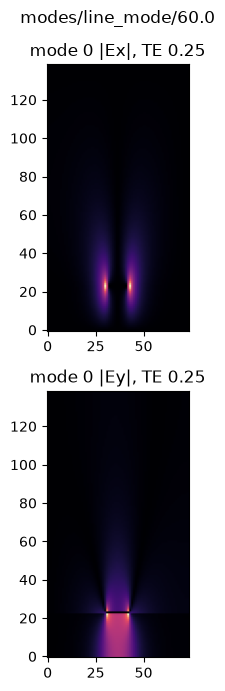

In [6]:
lumi.solve(path)

## Movie

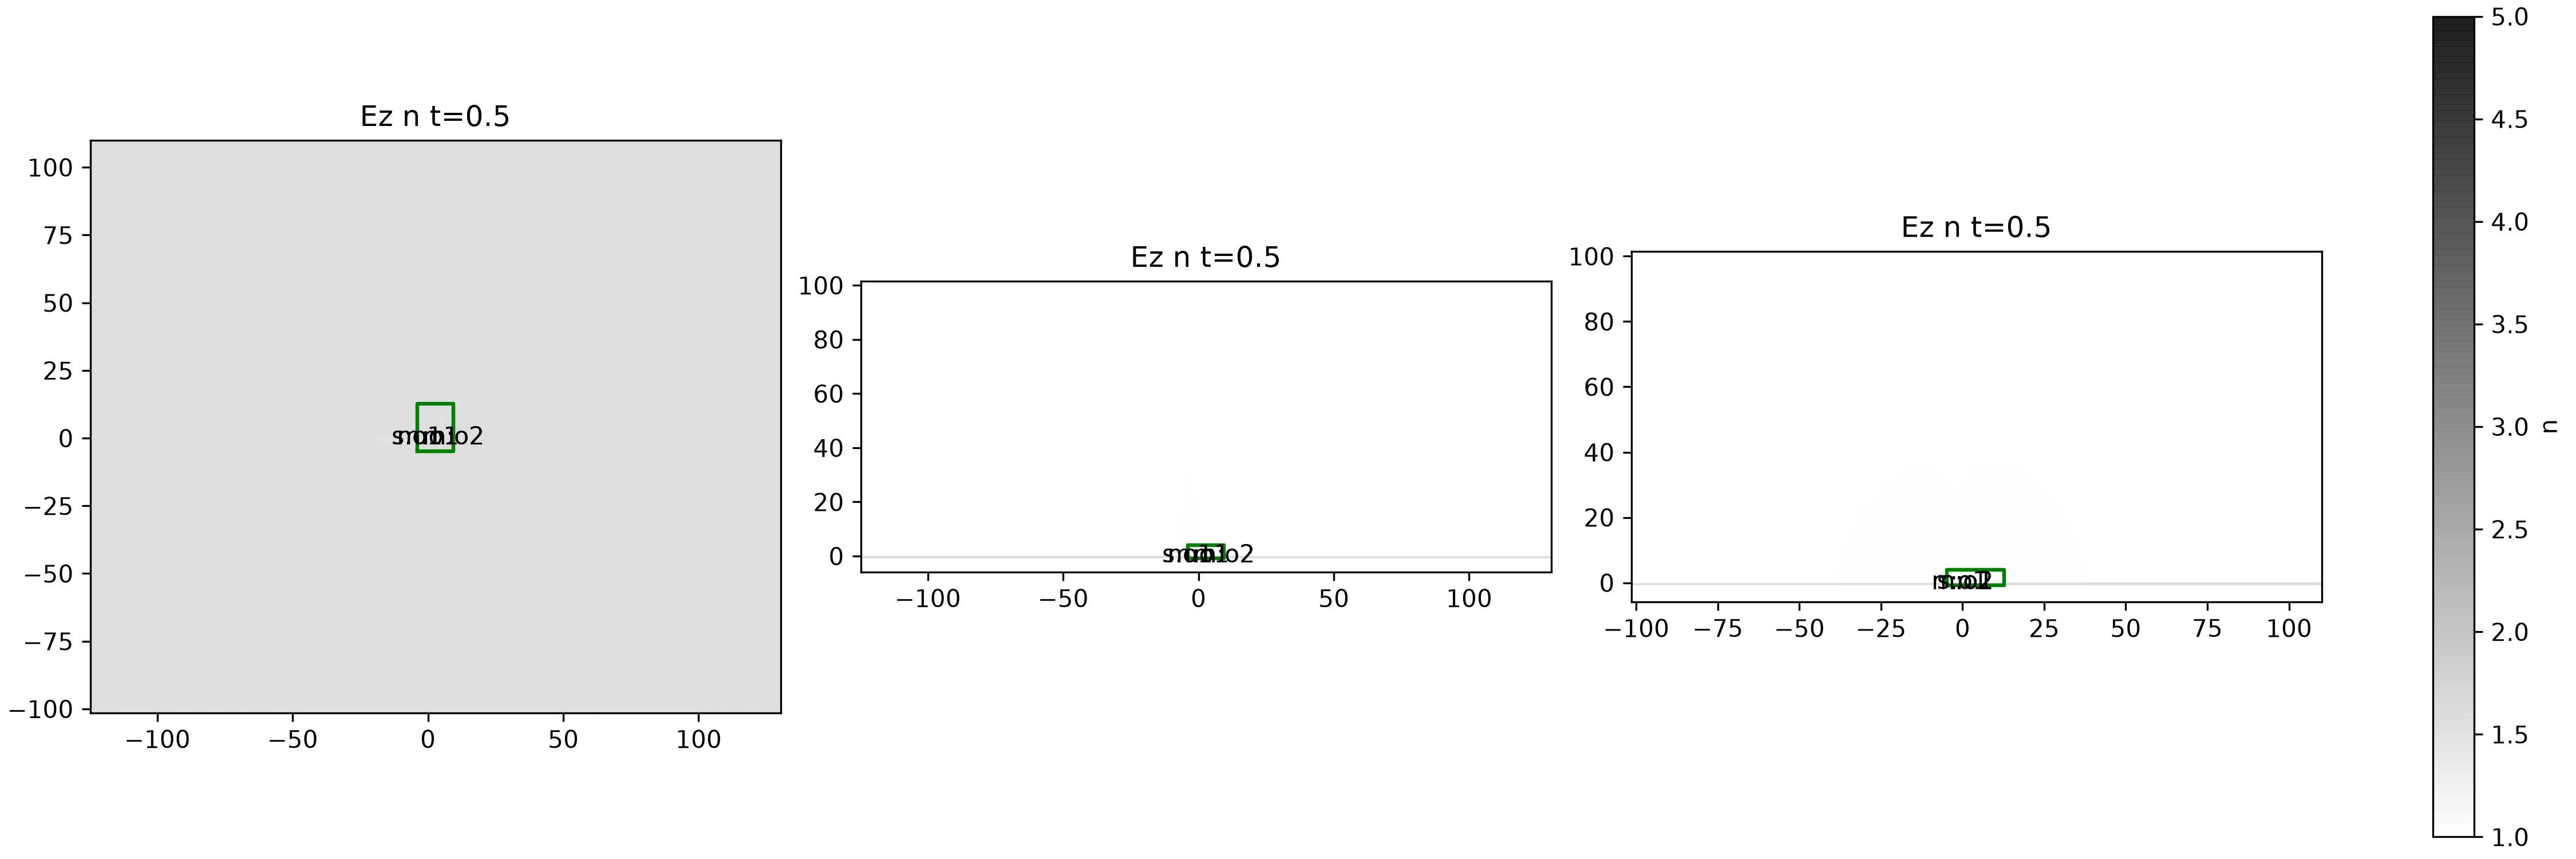

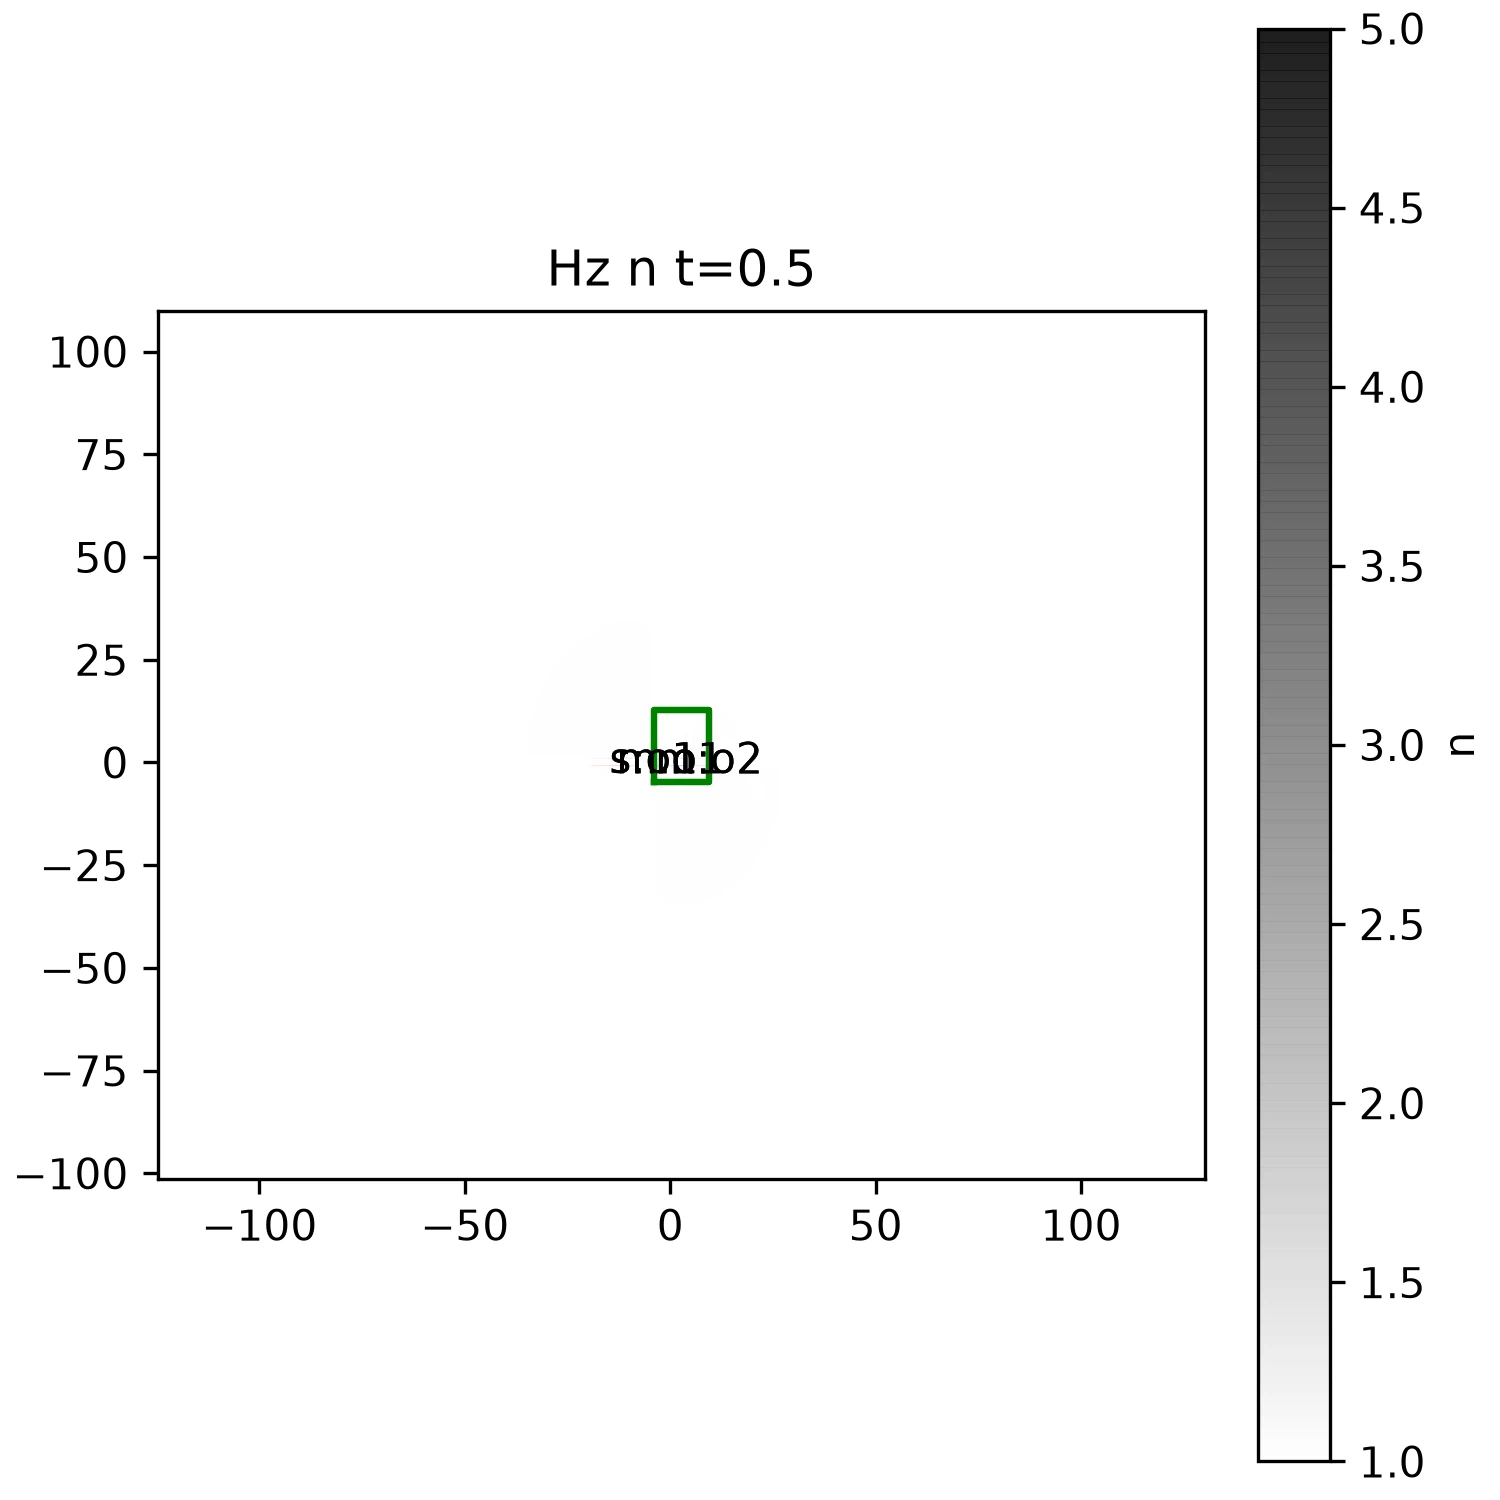

In [7]:
lumi.movie(path)

## Results

loading solution from runs/stub_filter
may take a minute if simulation folder is remotely mounted


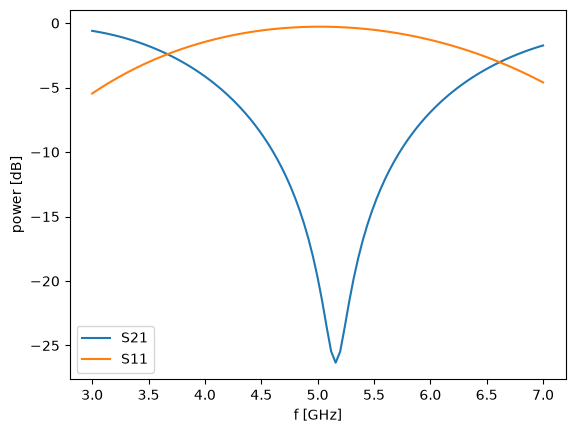

In [8]:
sol = lumi.load(path)
o1 = sol["monitors"]["o1"]
o2 = sol["monitors"]["o2"]

# + denotes outgoing mode (wrt port monitor outward normal), - incoming
S21 = o2["modes"][0]["+"] / o1["modes"][0]["-"]
S11 = o1["modes"][0]["+"] / o1["modes"][0]["-"]

plt.figure()
plt.plot(frequencies, 10 * np.log10(np.abs(S21)**2), label="S21")
plt.plot(frequencies, 10 * np.log10(np.abs(S11)**2), label="S11")
plt.xlabel("f [GHz]")
plt.ylabel("power [dB]")
plt.legend()
plt.show()